# EDA toàn bộ dữ liệu cục bộ trước khi chia tập nghiên cứu

Chạy trên **toàn bộ annotation/metadata đang materialized** của TED-LIUM, IIIT-CVID,
EduViQA, SlideVQA, VidChapters, YTSeg, Yale, MIT001 và TVSum. Split gốc của nhà phát hành
chỉ là thuộc tính nguồn; notebook **chưa tạo split nghiên cứu mới**.

Quét toàn bộ 270.323 dòng TED-LIUM, 5.475 frame/XML và 137.745 crop của IIIT-CVID,
toàn bộ danh sách annotation JSON/Parquet có trên máy, cùng metadata container của tất cả
video cục bộ. Không chạy mô hình. Không giải mã 53 GB waveform, mọi frame của video,
hoặc pickle 2 GB không đáng tin cậy. Những phần này được ghi là giới hạn, không gọi là đã kiểm tra.

Theo yêu cầu phân tích trước khi chia tập, thống kê tổng hợp có đọc trường reference trong
split gốc tên `test`. Vì vậy không được mô tả split gốc này là hoàn toàn chưa xem nhãn
trong một phép chọn cohort về sau.

In [1]:
from pathlib import Path
import hashlib, json, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'experiments/datasets').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Run inside the nested multimodal-lecture-summarizer repository')
sys.path.insert(0, str(ROOT))
from experiments.scripts.component_eda_audio import analyze_audio
from experiments.scripts.component_eda_visual import analyze_visual
from experiments.scripts.full_corpus_eda_visual_duplicates import screen_visual_duplicates
from experiments.scripts.full_corpus_eda_catalog import analyze_catalog
OUT = ROOT / 'experiments/outputs/full_corpus_eda_261003'
OUT.mkdir(parents=True, exist_ok=True)
def save(name, value):
    path = OUT / (name + '.json')
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
    return path
print('Repository:', ROOT)
print('EDA output:', OUT)

Repository: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\multimodal-lecture-summarizer
EDA output: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\multimodal-lecture-summarizer\experiments\outputs\full_corpus_eda_261003


## 1. Kiểm kê tất cả dataset và media cục bộ

In [2]:
catalog = analyze_catalog(ROOT)
save('catalog', catalog)
inventory = pd.DataFrame([
    {'dataset': name, 'files': item['files'], 'GiB': round(item['bytes']/2**30, 3),
     'top_extensions': ', '.join(f'{k}:{v}' for k,v in
                                sorted(item['extensions'].items(), key=lambda kv:-kv[1])[:4])}
    for name,item in catalog['inventory'].items()
]).sort_values('dataset')
display(inventory)
print('Total local GiB:', round(sum(x['bytes'] for x in catalog['inventory'].values())/2**30,2))
print('Inventory policy:', catalog['inventory_policy'])

,dataset,files,GiB,top_extensions
0,avlectures_mit001,5,0.000,".json:3, .py:1, .txt:1"
1,eduviqa,684,1.278,".jpg:581, .json:42, .pkl:20, .txt:20"
2,iiit_cvid,150394,4.495,".png:143220, .xml:5475, .txt:882, (none):813"
3,slidevqa,4,0.006,.json:4
4,tedlium3,134,49.331,".arrow:107, .wav:20, .json:7"
5,tvsum_extracted,0,0.000,
6,vidchapters_qualification,61,2.902,".wav:22, .jpg:19, .json:10, .mp4:8"
7,yale_rq1_qualification,268,13.334,".jpg:109, .json:102, .m4v:47, .mov:4"
8,ytseg_qualification,22,2.580,".mp4:10, .png:6, .parquet:4, .jpg:1"


Total local GiB: 73.93
Inventory policy: Recursive file inventory excludes .cache, .git and __pycache to avoid counting redundant caches.


In [3]:
other = [
 {'dataset':'EduViQA', 'annotation_units':catalog['eduviqa']['qa_pairs'],
  'local_videos':catalog['eduviqa']['media']['materialized_videos'],
  'reference':'Q&A; evidence provenance unresolved'},
 {'dataset':'SlideVQA', 'annotation_units':sum(x['qa_pairs'] for x in catalog['slidevqa']['splits']),
  'local_videos':0, 'reference':'Q&A; slide images missing'},
 {'dataset':'VidChapters', 'annotation_units':sum(catalog['vidchapters']['annotation_id_counts'].values()),
  'local_videos':catalog['vidchapters']['media']['materialized_videos'],
  'reference':'chapter payload is an untrusted 2 GB pickle, not parsed'},
 {'dataset':'YTSeg', 'annotation_units':catalog['ytseg']['annotation_rows'],
  'local_videos':catalog['ytseg']['media']['materialized_videos'],
  'reference':'creator chapters; not scene cuts'},
 {'dataset':'Yale', 'annotation_units':None, 'local_videos':catalog['yale']['media']['materialized_videos'],
  'reference':'qualification media, GT and rights need adjudication'},
 {'dataset':'MIT001', 'annotation_units':catalog['mit001']['gt_segments'],
  'local_videos':catalog['mit001']['actual_videos'],
  'reference':'chapter segments; 9 videos need review'},
 {'dataset':'TVSum', 'annotation_units':None, 'local_videos':0,
  'reference':'no materialized local media/annotations'},
]
display(pd.DataFrame(other))
print('EduViQA QA per video:',catalog['eduviqa']['qa_per_video'])
print('EduViQA question/answer words:',catalog['eduviqa']['question_words'],
      catalog['eduviqa']['answer_words'])
print('EduViQA transcript words:',catalog['eduviqa']['transcript_words'],
      'blank:',catalog['eduviqa']['blank_transcripts'],
      'repeat questions:',catalog['eduviqa']['repeated_questions_within_video'])
print('SlideVQA decks across native splits:',catalog['slidevqa']['deck_overlap'])
display(pd.DataFrame(catalog['slidevqa']['splits']))
print('VidChapters native ID counts:',catalog['vidchapters']['annotation_id_counts'])
print('YTSeg chapter count quantiles:',catalog['ytseg']['chapters_per_video'])
print('YTSeg zero-chapter rows:',catalog['ytseg']['rows_without_chapters'],
      'duplicate video ID rows:',catalog['ytseg']['annotation_rows']-catalog['ytseg']['unique_annotation_video_ids'])

,dataset,annotation_units,local_videos,reference
0,EduViQA,883.0,20,Q&A; evidence provenance unresolved
1,SlideVQA,14484.0,0,Q&A; slide images missing
2,VidChapters,817076.0,8,"chapter payload is an untrusted 2 GB pickle, n..."
3,YTSeg,16404.0,10,creator chapters; not scene cuts
4,Yale,NaN,51,"qualification media, GT and rights need adjudi..."
5,MIT001,277.0,35,chapter segments; 9 videos need review
6,TVSum,NaN,0,no materialized local media/annotations


EduViQA QA per video: {'0': 20.0, '0.25': 42.0, '0.5': 50.0, '0.75': 50.0, '0.95': 50.0, '1': 50.0}
EduViQA question/answer words: {'0': 8.0, '0.25': 13.0, '0.5': 14.0, '0.75': 16.0, '0.95': 19.0, '1': 24.0} {'0': 7.0, '0.25': 26.0, '0.5': 33.0, '0.75': 42.0, '0.95': 50.0, '1': 86.0}
EduViQA transcript words: {'0': 412.0, '0.25': 2240.0, '0.5': 3848.0, '0.75': 7151.0, '0.95': 7595.0, '1': 9534.0} blank: 0 repeat questions: 0
SlideVQA decks across native splits: {'train_val': 0, 'train_test': 0, 'val_test': 0}


,split,qa_pairs,decks,blank_questions,blank_answers,no_evidence_pages,question_words,answer_words
0,train,10617,1919,0,0,0,"{'0': 3.0, '0.25': 8.0, '0.5': 11.0, '0.75': 1...","{'0': 1.0, '0.25': 1.0, '0.5': 1.0, '0.75': 2...."
1,val,1652,300,0,0,0,"{'0': 3.0, '0.25': 9.0, '0.5': 12.0, '0.75': 1...","{'0': 1.0, '0.25': 1.0, '0.5': 1.0, '0.75': 2...."
2,test,2215,400,0,0,0,"{'0': 3.0, '0.25': 8.0, '0.5': 12.0, '0.75': 1...","{'0': 1.0, '0.25': 1.0, '0.5': 1.0, '0.75': 2...."


VidChapters native ID counts: {'train': 800676, 'val': 8200, 'test': 8200}
YTSeg chapter count quantiles: {'0': 0.0, '0.25': 5.0, '0.5': 7.0, '0.75': 10.0, '0.95': 17.0, '1': 56.0}
YTSeg zero-chapter rows: 5 duplicate video ID rows: 17


## 2. TED-LIUM: toàn bộ Arrow train/validation/test

In [4]:
audio = analyze_audio(ROOT)
save('tedlium3', audio)
columns = ['source_split','rows','valid_asr_rows','gap_rows','ignore_marker_rows',
           'unique_speakers','unique_source_files','segment_duration_sum_seconds',
           'merged_source_coverage_seconds','adjacent_interval_overlaps']
display(pd.DataFrame(audio['source_rows'])[columns])
display(pd.DataFrame(audio['cross_split_overlap']))
display(pd.DataFrame([
 {'split':row['source_split'], 'gender_codes':row['gender_code_counts'],
  'missing_speaker':row['missing_speaker_rows'],
  'missing_source':row['missing_source_file_rows'],
  'bad_timing':row['unparseable_or_nonpositive_timing_rows'],
  'repeated_reference_groups':row['repeated_reference_groups'],
  'rows_in_repeated_reference_groups':row['rows_in_repeated_reference_groups']}
 for row in audio['source_rows']
]))
for row in audio['source_rows']:
    print(row['source_split'],'top speakers:',row['top_speakers'],
          'segments/speaker:',row['segments_per_speaker_quantiles'])
print('Historical D2:', audio['historical_d2_units'], audio['historical_freeze_status'])
print('Readiness candidate:', audio['readiness_selected'], 'retained:', audio['readiness_retained'],
      'eligible:', audio['readiness_selection_eligible'])

Loading dataset from disk:   0%|          | 0/105 [00:00<?, ?it/s]

,source_split,rows,valid_asr_rows,gap_rows,ignore_marker_rows,unique_speakers,unique_source_files,segment_duration_sum_seconds,merged_source_coverage_seconds,adjacent_interval_overlaps
0,train,268263,268263,0,0,2351,2351,1633726.60,1602974.80,126201
1,validation,591,507,0,84,29,8,6173.10,6170.14,3
2,test,1469,1155,314,314,16,11,11006.86,11006.86,0


,left,right,same_ids,same_speakers,same_source_files,same_reference_strings
0,train,validation,0,0,0,4
1,train,test,0,0,0,6
2,validation,test,0,0,0,2


,split,gender_codes,missing_speaker,missing_source,bad_timing,repeated_reference_groups,rows_in_repeated_reference_groups
0,train,{'-1': 268263},0,0,0,1264,4970
1,validation,"{'2': 471, '1': 120}",0,0,0,1,2
2,test,"{'2': 913, '0': 314, '1': 237, '-1': 5}",0,0,0,1,3


train top speakers: {'FrankGehry_1990': 414, 'EdwardBurtynsky_2005': 310, 'GretchenCarlsonandDavidBrooks_2017S': 299, 'YuvalNoahHarari_2017S': 298, 'RichardLedgett_2014': 286, 'BillStrickland_2002': 284, 'AmoryLovins_2012S': 278, 'ChimamandaNgoziAdichie_2012X': 278, 'Bono_2005': 270, 'EdwardSnowden_2014': 269} segments/speaker: {'0': 9.0, '0.25': 78.0, '0.5': 120.0, '0.75': 149.0, '0.95': 187.5, '1': 414.0}
validation top speakers: {'Barry_Schwartz': 106, 'Wade_Davis': 90, 'Elizabeth_Gilbert': 82, 'Craig_Venter': 76, 'David_Merrill': 44, 'Blaise_Agueray_Arcas': 38, 'Al_Gore': 28, 'S54': 17, 'Brian_Cox': 16, 'S115': 14} segments/speaker: {'0': 1.0, '0.25': 2.0, '0.5': 7.0, '0.75': 17.0, '0.95': 86.79999999999998, '1': 106.0}
test top speakers: {'inter_segment_gap': 314, 'DanBarber': 235, 'BillGates': 151, 'AimeeMullins': 129, 'DanielKahneman': 127, 'MichaelSpecter': 124, 'JaneMcGonigal': 108, 'JamesCameron': 95, 'EricMead_2009P_EricMead': 52, 'RobertGupta': 37} segments/speaker: {'0': 1

,split,variable,0,0.25,0.5,0.75,0.95,1
0,train,duration_seconds,0.540000,3.700000,5.960000,8.240000,10.790000,30.000000
1,train,reference_words,1.000000,10.000000,17.000000,25.000000,38.000000,91.000000
2,train,words_per_second,0.033333,2.374835,2.898551,3.448276,4.306220,12.030075
3,validation,duration_seconds,0.470000,6.335000,10.070000,13.775000,21.495000,39.920000
4,validation,reference_words,1.000000,21.000000,33.000000,46.000000,73.000000,126.000000
5,validation,words_per_second,0.478469,2.650087,3.090909,3.528029,4.262890,6.382979
6,test,duration_seconds,0.200000,2.540000,6.920000,10.300000,14.966000,330.190000
7,test,reference_words,1.000000,13.000000,24.000000,34.000000,49.000000,126.000000
8,test,words_per_second,0.544959,2.495841,2.994439,3.482025,4.273549,5.830389


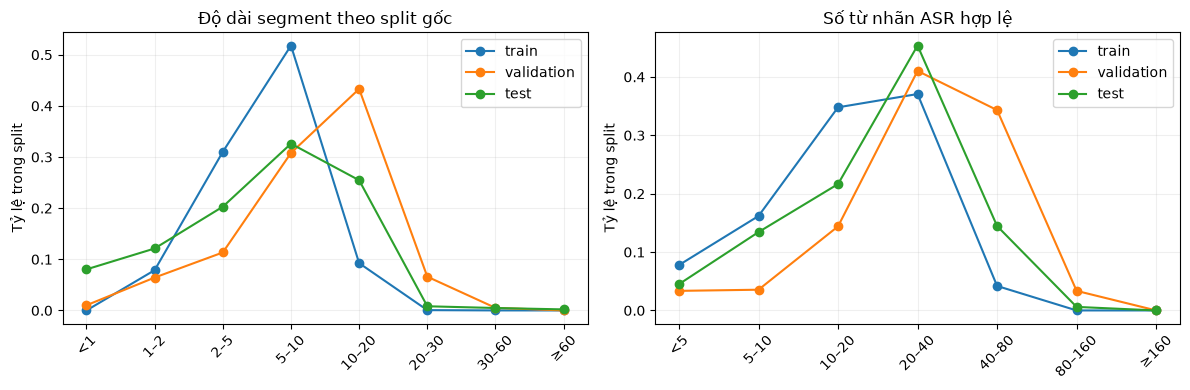

In [5]:
quantiles=[]
for row in audio['source_rows']:
    for label,key in [('duration_seconds','duration_quantiles_seconds'),
                      ('reference_words','reference_word_quantiles'),
                      ('words_per_second','wps_quantiles')]:
        quantiles.append({'split':row['source_split'],'variable':label,**row[key]})
display(pd.DataFrame(quantiles))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for row in audio['source_rows']:
    count=row['duration_histogram']
    axes[0].plot(range(len(count)),[v/sum(count) for v in count],marker='o',label=row['source_split'])
    count=row['reference_word_histogram']
    axes[1].plot(range(len(count)),[v/sum(count) for v in count],marker='o',label=row['source_split'])
axes[0].set_xticks(range(8),['<1','1–2','2–5','5–10','10–20','20–30','30–60','≥60'],rotation=45)
axes[1].set_xticks(range(7),['<5','5–10','10–20','20–40','40–80','80–160','≥160'],rotation=45)
axes[0].set_title('Độ dài segment theo split gốc');axes[1].set_title('Số từ nhãn ASR hợp lệ')
for ax in axes:ax.set_ylabel('Tỷ lệ trong split');ax.legend();ax.grid(alpha=.2)
plt.tight_layout();display(fig);plt.close(fig)

**Đọc bảng ASR:** `ignore_time_segment_in_scoring` và `inter_segment_gap` là ký hiệu không chấm ASR.
Tổng thời lượng segment có chồng lấn, vì vậy dùng `merged_source_coverage_seconds` để
mô tả vùng thời gian được phủ; nó vẫn không chứng minh toàn bộ 53 GB audio đã giải mã.

## 3. IIIT-CVID: toàn bộ frame/XML và crop/nhãn

In [6]:
visual = analyze_visual(ROOT)
save('iiit_cvid', visual)
display(pd.DataFrame([
 {k:row[k] for k in ['source_split','frames','xml_files','courses','videos','text_lines',
                     'text_words','blank_text_lines','invalid_boxes','xml_size_mismatches']}
 for row in visual['frames']
]))
display(pd.DataFrame([
 {k:row[k] for k in ['source_split','crop_files','label_rows','unique_label_paths',
                     'missing_labeled_images','blank_labels','unique_label_strings',
                     'non_ascii_labels','numeric_labels']}
 for row in visual['crops']
]))
display(pd.DataFrame(visual['source_split_overlap']))

,source_split,frames,xml_files,courses,videos,text_lines,text_words,blank_text_lines,invalid_boxes,xml_size_mismatches
0,train,3171,3171,12,395,82263,82484,0,18,23
1,val,549,549,5,140,15379,15415,0,3,3
2,test,1755,1755,7,276,40103,40117,0,1,98


,source_split,crop_files,label_rows,unique_label_paths,missing_labeled_images,blank_labels,unique_label_strings,non_ascii_labels,numeric_labels
0,train,82263,82263,82263,0,0,12240,0,2679
1,val,15379,15379,15379,0,0,3851,0,1274
2,test,40103,40103,40103,0,0,7915,0,2044


,left,right,same_courses,same_videos
0,train,val,0,0
1,train,test,0,0
2,val,test,0,0


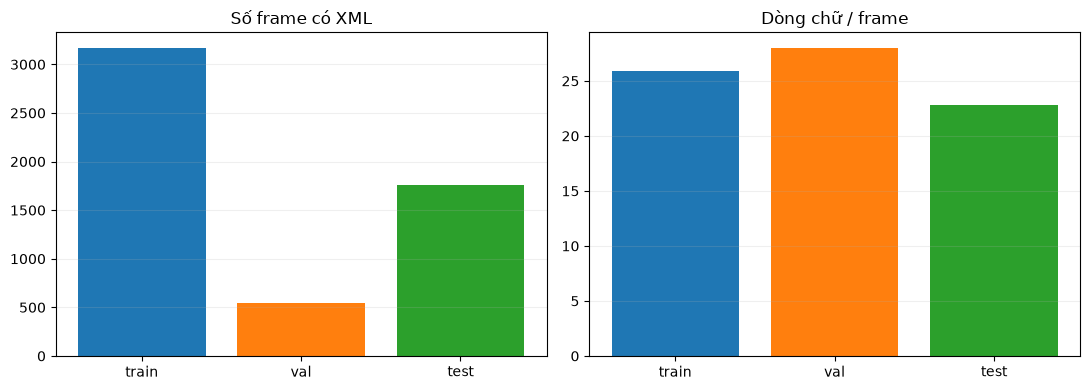

train frame/course: {'1': 247, '12': 205, '15': 102, '16': 209, '17': 170, '21': 581, '22': 252, '23': 449, '4': 167, '5': 293, '8': 332, '9': 164} line/frame quantiles: {'0': 2.0, '0.25': 12.0, '0.5': 21.0, '0.75': 35.0, '0.95': 61.0, '1': 165.0} geometry: {'0': 640.0, '0.25': 720.0, '0.5': 787.0, '0.75': 1280.0, '0.95': 1920.0, '1': 1920.0} {'0': 386.0, '0.25': 482.0, '0.5': 578.0, '0.75': 738.0, '0.95': 1090.0, '1': 1090.0}
  Invalid boxes: [{'relative_path': '1\\1\\01_13_20_00010.png', 'invalid_boxes': 2}, {'relative_path': '1\\15\\00_57_10_00011.png', 'invalid_boxes': 1}, {'relative_path': '1\\17\\00_32_39_00008.png', 'invalid_boxes': 1}, {'relative_path': '1\\19\\01_00_02_00008.png', 'invalid_boxes': 1}, {'relative_path': '1\\2\\00_15_56_00005.png', 'invalid_boxes': 1}, {'relative_path': '1\\20\\00_57_38_00010.png', 'invalid_boxes': 1}, {'relative_path': '1\\21\\01_14_52_00013.png', 'invalid_boxes': 1}, {'relative_path': '1\\6\\00_26_59_00006.png', 'invalid_boxes': 2}, {'relative

In [7]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for row in visual['frames']:
    axes[0].bar(row['source_split'],row['frames'],label=row['source_split'])
    axes[1].bar(row['source_split'],row['text_lines']/row['frames'])
axes[0].set_title('Số frame có XML'); axes[1].set_title('Dòng chữ / frame')
for ax in axes:ax.grid(axis='y',alpha=.2)
plt.tight_layout();display(fig);plt.close(fig)
for row in visual['frames']:
    print(row['source_split'],'frame/course:',row['frames_per_course'],
          'line/frame quantiles:',row['lines_per_frame_quantiles'],
          'geometry:',row['width_quantiles'],row['height_quantiles'])
    if row['invalid_box_frames']:
        print('  Invalid boxes:',row['invalid_box_frames'])
    if row['xml_size_mismatch_examples']:
        print('  XML size mismatch examples:',row['xml_size_mismatch_examples'][:10])
for row in visual['crops']:
    print(row['source_split'],'crop label length:',row['label_length_quantiles'],
          'top labels:',row['top_labels'][:8],
          'crop dimensions:',row['top_image_dimensions'][:5])

## 4. Kiểm tra trùng ảnh trên toàn bộ 5.475 frame

In [8]:
duplicates = screen_visual_duplicates(ROOT)
save('iiit_cvid_duplicates', duplicates)
display(pd.DataFrame([{k:v for k,v in duplicates.items()
                       if k not in ('near_cross_split_examples','exact_cross_split_examples',
                                    'interpretation')}]))
display(pd.DataFrame(duplicates['near_cross_split_examples']))
print(duplicates['interpretation'])

,frames_scanned,method,threshold,exact_duplicate_groups,exact_cross_split_groups,near_cross_split_pairs,near_cross_split_pairs_high_text_overlap,near_within_split_pairs,near_cross_split_affected_frames
0,5475,64_bit_dhash_hamming_at_most_6,6,0,0,469,0,9474,263


,left,right,hamming,text_jaccard
0,train\16\18\00_12_50_00002.png,test\10\29\00_09_30_00002.png,6,0.0000
1,train\16\18\00_12_50_00002.png,test\10\3\00_29_28_00005.png,6,0.0000
2,train\17\19\00_58_18_00007.png,test\10\32\00_29_17_00008.png,6,0.0312
3,train\17\21\00_49_27_00006.png,test\14\23\00_07_41_00003.png,6,0.0000
4,train\17\22\01_05_42_00006.png,test\14\18\00_14_27_00004.png,6,0.0000
5,train\17\25\00_27_28_00005.png,val\13\1\00_32_14_00004.png,6,0.0588
6,train\17\25\00_27_28_00005.png,test\14\23\00_07_41_00003.png,6,0.0000
7,train\17\35\00_54_41_00007.png,val\13\4\00_52_12_00004.png,6,0.0476
8,train\21\13\00_15_11_00005.png,test\14\18\00_14_27_00004.png,6,0.0222
9,train\21\13\00_48_24_00010.png,test\14\18\00_14_27_00004.png,6,0.0000


A dHash match is a review candidate; it does not prove two frames carry the same text or lecture content.


**Diễn giải trùng ảnh:** SHA-256 nhận diện bản sao byte chính xác. dHash khoảng cách Hamming ≤6
chỉ nêu cặp cần xem lại; slide có bố cục giống nhau có thể khác nội dung. Không tự loại
frame chỉ dựa trên dHash.

## 5. Quyết định sau EDA, trước khi chia tập

In [9]:
decisions = pd.DataFrame([
 {'endpoint':'ASR','dataset':'TED-LIUM','decision':'dùng để thiết kế benchmark',
  'reason':'270.323 segment; lọc 398 nhãn không chấm; chia theo nguồn/diễn giả; chưa kiểm tra toàn bộ waveform'},
 {'endpoint':'OCR','dataset':'IIIT-CVID','decision':'dùng để thiết kế benchmark',
  'reason':'frame/XML và crop có nhãn đầy đủ; box/XML size bất thường và dHash cần phân xử'},
 {'endpoint':'scene cut / keyframe / caption','dataset':'các nguồn video cục bộ',
  'decision':'chưa có GT đúng tác vụ',
  'reason':'chapter/QA/transition thuật toán không thay nhãn scene, keyframe, caption độc lập'},
 {'endpoint':'QA','dataset':'EduViQA / SlideVQA','decision':'khảo sát riêng',
  'reason':'EduViQA có 883 QA trên 20 video; SlideVQA 14.484 QA nhưng thiếu ảnh slide'},
])
display(decisions)
print('No research split or model ranking was created by this notebook.')

,endpoint,dataset,decision,reason
0,ASR,TED-LIUM,dùng để thiết kế benchmark,270.323 segment; lọc 398 nhãn không chấm; chia...
1,OCR,IIIT-CVID,dùng để thiết kế benchmark,frame/XML và crop có nhãn đầy đủ; box/XML size...
2,scene cut / keyframe / caption,các nguồn video cục bộ,chưa có GT đúng tác vụ,chapter/QA/transition thuật toán không thay nh...
3,QA,EduViQA / SlideVQA,khảo sát riêng,EduViQA có 883 QA trên 20 video; SlideVQA 14.4...


No research split or model ranking was created by this notebook.


In [10]:
scripts = ['experiments/scripts/component_eda_audio.py',
           'experiments/scripts/component_eda_visual.py',
           'experiments/scripts/full_corpus_eda_visual_duplicates.py',
           'experiments/scripts/full_corpus_eda_catalog.py']
artifacts = ['catalog.json','tedlium3.json','iiit_cvid.json','iiit_cvid_duplicates.json']
provenance = ['experiments/datasets/tedlium3/provenance.json',
              'experiments/datasets/iiit_cvid/provenance.json',
              'experiments/datasets/slidevqa/provenance.json',
              'experiments/datasets/tedlium3/train/state.json',
              'experiments/datasets/tedlium3/validation/state.json',
              'experiments/datasets/tedlium3/test/state.json']
receipt = {
 'status':'executed_full_local_corpus_eda_with_declared_limits',
 'source_splits_analyzed':['train','validation','test'],
 'research_split_created':False, 'model_inference_run':False,
 'native_test_reference_aggregates_accessed':True,
 'script_sha256':{name:hashlib.sha256((ROOT/name).read_bytes()).hexdigest() for name in scripts},
 'source_metadata_sha256':{name:hashlib.sha256((ROOT/name).read_bytes()).hexdigest() for name in provenance},
 'artifact_sha256':{name:hashlib.sha256((OUT/name).read_bytes()).hexdigest() for name in artifacts},
 'artifact_root':str(OUT),
}
save('eda_receipt',receipt)
display(pd.DataFrame([{'artifact':k,'sha256':v} for k,v in receipt['artifact_sha256'].items()]))
print('Receipt saved:',OUT/'eda_receipt.json')

,artifact,sha256
0,catalog.json,34869e6329d70fcba92a1392d8837cf936e44c838a803d...
1,tedlium3.json,94a6262db8768771b57aab6deec7a3b822480b13660947...
2,iiit_cvid.json,462f70792f9a9a6ff492de3e7c0118aec211037b6044b9...
3,iiit_cvid_duplicates.json,e348a19e580232646639ec11f2db27ce28ce3a46548f5c...


Receipt saved: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\multimodal-lecture-summarizer\experiments\outputs\full_corpus_eda_261003\eda_receipt.json


### Giới hạn và câu hỏi còn mở

- TED-LIUM: metadata/nhãn đã quét toàn bộ; chưa giải mã 53 GB waveform hoặc kiểm tra trùng âm thanh.
- IIIT-CVID: toàn bộ frame/XML và header crop đã đọc; chưa giải mã đầy đủ từng crop hay xác nhận thủ công các cặp dHash.
- VidChapters: ID JSON đã đếm toàn bộ, nhưng `chapters.pkl` 2 GB chưa giải tuần tự an toàn; chỉ 8 video cục bộ.
- Video khác: metadata container đã đọc, chưa giải mã mọi frame. TVSum rỗng, SlideVQA thiếu ảnh.
- Phải quyết định nghiên cứu dùng split mới theo talk/course/video; các split gốc đã được dùng cho EDA nhãn tổng hợp.